In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import json
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score, confusion_matrix

from src.mass_detect.scripts.config import CENTRE_INDEX, LIDC_MANIFEST_FILE, LNDB_MANIFEST_FILE, MODEL_RESULTS_DIR, PATCHES_DIR, ROI_DIR
from src.mass_detect.scripts.modelling import edge_share, flat, make_model
from IPython.display import display
from src.mass_detect.scripts.run_models import load_tables, run as run_models

pd.set_option("display.width", 160)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Models and Validation
  </h1>
  <p>
  This notebook learns the malignancy rating from the features of notebook 05 and measures how well it does on both datasets. Every choice is made with the same nested cross validation and the same rule fixed in advance, in six stages: the decision rule, the way of pooling LNDb and LIDC IDRI, the model, the training label, the 1 to 3 scale and three extensions of the chosen model. The chosen configuration is then confirmed on new splits and interpreted.
  </p>
  <p>
  The functions live in <strong>src/mass_detect/scripts/modelling.py</strong> (models, pooling, decision rules, nested cross validation, bootstrap) and <strong>run_models.py</strong> (the stages). The comparisons take a few hours, so they run from the terminal and save their results, which this notebook reads.
  </p>
</div>

In [2]:
# Unit tests of the ordinal model (test_models.py), and of the ordinal wrapper, the decision rules,
# the pooling and the nested cross validation (test_modelling.py)
from src.mass_detect.tests import test_modelling, test_models

tests = [test_models.test_probabilities_are_valid,
         test_models.test_recovers_the_true_weights_and_cut_points,
         test_models.test_cut_points_stay_in_order]
tests += [getattr(test_modelling, name) for name in dir(test_modelling) if name.startswith("test_")]
for test in tests:
    test()
print(f"{len(tests)} tests passed")

16 tests passed


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The data
  </h3>
  <p>
  One row per nodule of the cohort (notebook 03) with the features kept in notebook 05, its diameter, its label on both scales, its patient and dataset, and one row per reading for the training on single readings.
  </p>
</div>

In [3]:
nodules, readings, features = load_tables()
print(f"{len(nodules)} nodules from {nodules['patient_id'].nunique()} patients, "
      f"{len(readings)} readings, {len(features)} features")

# Number of nodules of each rating, per dataset
nodules.groupby("dataset")["rating"].value_counts().unstack()

3237 nodules from 1062 patients, 7585 readings, 63 features


rating,1,2,3,4,5
dataset,,,,,
LIDC,286,603,1237,387,102
LNDb,138,197,199,70,18


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How far can a model go? The agreement between two radiologists
  </h3>
  <p>
  The label is a subjective rating, and a model trained on ratings cannot be expected to agree with a radiologist better than two radiologists agree with each other. For every nodule of the cohort read by two or more radiologists we compare every pair of readers, on both scales. This is the realistic ceiling of the models.
  </p>
</div>

In [4]:
def to_three(rating):
    """1 to 5 rating to the 1 to 3 scale: 1 and 2 benign, 3 indeterminate, 4 and 5 suspicious."""
    return np.digitize(rating, [2.5, 3.5]) + 1

def qwk(a, b):
    return cohen_kappa_score(a, b, weights="quadratic")

rated = readings.dropna(subset=["reader_rating"])
ceiling = {}
for dataset, group in rated.groupby("dataset"):
    first, second = [], []      # every pair of radiologists who rated the same nodule
    single, others = [], []     # one radiologist against the mean of the other radiologists, rounded half up
    for _, ratings in group.groupby("patch_id")["reader_rating"]:
        values = ratings.to_numpy(dtype=int)
        if len(values) < 2:
            continue
        for i in range(len(values)):
            rest = np.delete(values, i)
            single.append(values[i])
            others.append(int(np.floor(rest.mean() + 0.5)))
            for j in range(i + 1, len(values)):
                first.append(values[i])
                second.append(values[j])
    first, second = np.array(first), np.array(second)
    single, others = np.array(single), np.array(others)
    ceiling[dataset] = {
        "pairs": len(first),
        "QWK 1 to 5": qwk(first, second),
        "QWK 1 to 3": qwk(to_three(first), to_three(second)),
        "one against the others, 1 to 5": qwk(single, others),
        "one against the others, 1 to 3": qwk(to_three(single), to_three(others)),
    }
ceiling = pd.DataFrame(ceiling).T
ceiling.round(3)

,pairs,QWK 1 to 5,QWK 1 to 3,"one against the others, 1 to 5","one against the others, 1 to 3"
LIDC,7207.0,0.458,0.311,0.527,0.40
LNDb,307.0,0.525,0.437,0.527,0.42


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Two radiologists who read the same nodule agree with a QWK of 0.525 in LNDb and 0.458 in LIDC IDRI on the 1 to 5 scale, and of 0.437 and 0.311 on the 1 to 3 scale. Agreement is only moderate, as expected for a subjective rating, and lower in LIDC IDRI, where up to four radiologists read each scan independently.
  </p>
  <p>
  These pairwise values are not a hard upper limit for the models. A model is compared with the label, which is the rounded mean of up to four ratings, and averaging removes part of the disagreement of each single reader. The fairer reference is therefore one radiologist against the rounded mean of the other radiologists of the same nodule: 0.527 in both datasets on the 1 to 5 scale, and 0.42 in LNDb and 0.40 in LIDC IDRI on the 1 to 3 scale. It is still a conservative reference, because the label of the model averages one more reader than the mean of the others. The figures below draw the pairwise values as dotted lines.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How we validate and choose
  </h3>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Nested cross validation grouped by patient.</strong> The outer loop (5 folds, stratified by dataset and rating, repeated with 3 seeds) estimates the performance: every nodule is predicted once per seed by a model that never saw its patient, because nodules of one patient share scanner, anatomy and readers (Kapoor and Narayanan, 2023). The inner loop, inside each outer training part, only chooses the hyperparameters and the decision rule, so the outer folds never take part in any choice (Cawley and Talbot, 2010).</li>
    <li style="margin-bottom: 8px;"><strong>How the inner loop chooses.</strong> The outer training part is split into 3 folds grouped by patient, and the split is drawn twice with two seeds, so every candidate is scored on 6 held out folds. One inner fold holds only about 166 LNDb nodules, four or five of them rated 5, so the score of a single split is noisy, and repeating the split makes the choice more stable (Krstajic et al., 2014). The score of a candidate is the mean of its 6 fold scores, with the standard error of that mean. The choice follows the one standard error rule (Hastie et al., 2009): among the candidates whose score is within one standard error of the best, the simplest wins, which for the ordinal model means the strongest penalty. A gain smaller than the noise of the inner folds is not a reason to choose a more complex model, the same principle as the rule of every stage below.</li>
    <li style="margin-bottom: 8px;"><strong>The grids.</strong> The penalty of the ordinal model is searched over ten values from 0.1 to 3000, evenly spaced on a logarithmic scale, because its effect depends on its order of magnitude. A grid is too narrow when one of its two ends is chosen in more than 20% of the outer folds, because the best value may then lie beyond it; this check is fixed in advance and reported below. When each dataset has its own model, each model has its own hyperparameters.</li>
    <li style="margin-bottom: 8px;"><strong>Primary metric, fixed in advance:</strong> the mean of the QWK in LNDb and the QWK in LIDC IDRI on the 1 to 5 scale. The QWK penalises an error by its distance (Cohen, 1968) and is directly comparable with the agreement between radiologists; computing it in each dataset and averaging gives both datasets the same weight, so pooling cannot hide a loss in LNDb. Balanced accuracy, macro F1 and MAE are reported as well.</li>
    <li style="margin-bottom: 8px;"><strong>Uncertainty:</strong> 95% intervals from resampling whole patients 1000 times (Field and Welsh, 2007). Two options are compared through their difference on the same resampled patients, which is more precise than comparing two intervals.</li>
    <li style="margin-bottom: 8px;"><strong>The rule of every stage, fixed in advance:</strong> the option with the best mean QWK is kept, unless the 95% interval of its difference to the simplest option includes zero, in which case the simplest is kept. The chosen configuration is finally evaluated on three new seeds, to see how optimistic the choices were.</li>
  </ul>
</div>

In [5]:
# The comparisons run from the terminal (src/mass_detect/scripts/run_models.py); they are computed here only if missing
if not (MODEL_RESULTS_DIR / "summary.csv").exists():
    run_models()
summary = pd.read_csv(MODEL_RESULTS_DIR / "summary.csv").set_index("config")
chosen = json.loads((MODEL_RESULTS_DIR / "chosen.json").read_text())

columns = ["mean_qwk", "low", "high", "qwk_LNDb", "qwk_LIDC",
           "balanced_accuracy_LNDb", "balanced_accuracy_LIDC", "mae_LNDb", "mae_LIDC"]
difference = ["difference", "difference_low", "difference_high"]


def stage_table(prefix):
    """The rows of one stage, with the main metrics and the difference to the reference of the stage."""
    rows = summary[summary.index.str.startswith(prefix)]
    shown = [column for column in columns + difference if column in rows]
    return rows[shown].round(3)


def stage_figure(table, title):
    """Mean QWK with its 95% interval (black), the QWK of each dataset, and the agreement between two radiologists."""
    x = np.arange(len(table))
    below = table["mean_qwk"] - table["low"]
    above = table["high"] - table["mean_qwk"]

    fig, ax = plt.subplots(figsize=(1.4 * len(table) + 2, 3.5))
    ax.errorbar(x, table["mean_qwk"], yerr=[below, above], fmt="o", color="black", label="mean QWK (95% interval)")
    ax.scatter(x, table["qwk_LNDb"], marker="s", alpha=0.7, label="LNDb")
    ax.scatter(x, table["qwk_LIDC"], marker="^", alpha=0.7, label="LIDC")
    ax.axhline(ceiling.loc["LNDb", "QWK 1 to 5"], color="tab:blue", linestyle=":", linewidth=1, label="two radiologists, LNDb")
    ax.axhline(ceiling.loc["LIDC", "QWK 1 to 5"], color="tab:orange", linestyle=":", linewidth=1, label="two radiologists, LIDC")
    ax.set_xticks(x, [name.split("_", 1)[1] for name in table.index], rotation=20)
    ax.set(ylabel="QWK", title=title)
    ax.legend(fontsize=7, loc="lower right")
    plt.tight_layout()
    plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Baselines
  </h3>
  <p>
  Size is the strongest single predictor of malignancy, and a model that only uses the diameter is a strong baseline on LIDC IDRI (Baltatzis et al., 2021). Every model has to beat the ordinal logistic regression on the diameter of the consensus region alone. The second reference is the same model on every kept feature (McCullagh, 1980), with an L2 penalty.
  </p>
</div>

In [6]:
# The diameter alone against the ordinal model on every feature (difference: diameter minus every feature)
summary.loc[["baseline_diameter", "rule_tuned"], columns + difference].round(3)

,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
baseline_diameter,0.369,0.324,0.416,0.329,0.408,0.29,0.312,0.730,0.640,-0.212,-0.257,-0.165
rule_tuned,0.581,0.535,0.617,0.551,0.611,0.40,0.406,0.592,0.485,0.000,0.000,0.000


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The diameter alone reaches a mean QWK of 0.369 (95% interval from 0.324 to 0.416), with 0.329 in LNDb and 0.408 in LIDC IDRI. The ordinal model on the 63 kept features reaches 0.581 (from 0.535 to 0.617), 0.212 more than the diameter, with an interval of the difference from 0.165 to 0.257. The texture, intensity and shape features therefore add a lot to size, which is the strongest single feature but leaves most of the rating unexplained.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 0: the decision rule
  </h3>
  <p>
  The model gives a probability for each rating, and one rating has to be chosen. Three rules are compared:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>argmax</strong>, the most probable rating: optimal for accuracy and more willing to predict the extreme ratings, but blind to distance (with probabilities 0.35, 0.10, 0.15, 0.20 and 0.20 it predicts 1 although most of the mass lies on 3 to 5);</li>
    <li style="margin-bottom: 8px;"><strong>median</strong>, the first rating whose cumulative probability reaches 0.5: it minimises the expected absolute error (Gneiting, 2011), so it suits ordinal metrics, but it predicts the extreme ratings less often;</li>
    <li style="margin-bottom: 8px;"><strong>mean</strong>, the expected rating rounded half up: it minimises the expected squared error, which is what the QWK penalises, and pulls even more towards the middle.</li>
  </ul>
  <p>
  Each rule is evaluated alone, and the rule is also left for the inner folds to choose ("tuned"). From stage 1 on, the inner folds choose the rule, because it costs nothing: the model is not refitted, only its probabilities are read differently.
  </p>
</div>

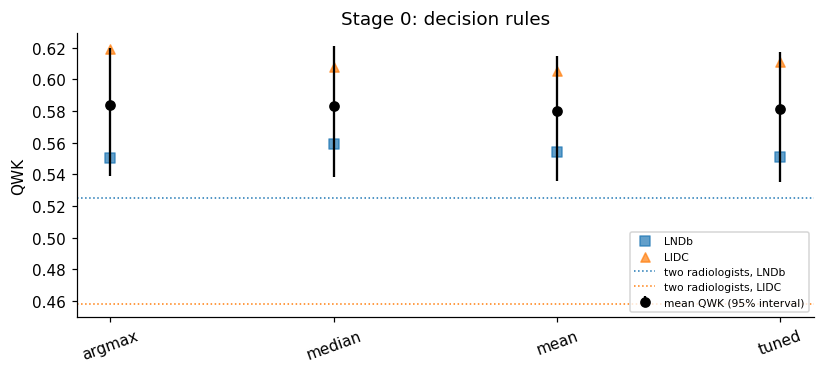

,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
rule_argmax,0.584,0.539,0.620,0.550,0.619,0.400,0.416,0.599,0.475,0.003,-0.001,0.008
rule_median,0.583,0.538,0.621,0.559,0.608,0.401,0.403,0.582,0.490,0.002,-0.005,0.010
rule_mean,0.580,0.536,0.615,0.554,0.605,0.394,0.394,0.587,0.500,-0.001,-0.013,0.009
rule_tuned,0.581,0.535,0.617,0.551,0.611,0.400,0.406,0.592,0.485,0.000,0.000,0.000


In [7]:
table = stage_table("rule_")
stage_figure(table, "Stage 0: decision rules")
table

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The three rules give close results: argmax 0.584, median 0.583 and mean 0.580, against 0.581 when the inner folds choose. No rule differs from the tuned one: every interval of the difference includes zero (for the mean, from 0.013 lower to 0.009 higher). The mean pulls the predictions towards the middle ratings, which shows in its balanced accuracy, the lowest of the three (0.394 in both datasets, against 0.400 in LNDb and 0.416 in LIDC IDRI for argmax). As planned, the inner folds choose the rule from stage 1 on, at no cost; here they chose argmax in 9 of the 15 outer folds, the median in 5 and the mean in 1.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 1: how to use LNDb and LIDC IDRI together
  </h3>
  <p>
  LNDb alone has 622 nodules and only 18 rated 5; LIDC IDRI adds 2615 nodules and 102 rated 5. The two datasets come from different scanners and different reading habits (47% of the LIDC IDRI nodules are rated 3, against 32% in LNDb), so pooling them can help or hurt. With the ordinal model, we compare:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>each dataset alone</strong>, as a reference;</li>
    <li style="margin-bottom: 8px;"><strong>plain pooling</strong>, both datasets as they are;</li>
    <li style="margin-bottom: 8px;"><strong>a dataset indicator</strong>, one more column that lets the model shift its thresholds for LIDC IDRI;</li>
    <li style="margin-bottom: 8px;"><strong>ComBat harmonisation</strong> (Johnson et al., 2007; Orlhac et al., 2022) with LIDC IDRI as the reference batch, because it is the larger dataset: the LNDb features are moved onto the scale of LIDC IDRI, which stays unchanged (Zhang et al., 2018). The log diameter of the consensus region is kept as the biological covariate, so that size differences between the datasets are not removed as if they were scanner effects. The rating is not used as covariate, because the LNDb nodules that are adjusted are also validated, and their rating cannot be known when they are adjusted. ComBat is fitted on the training part of every fold only;</li>
    <li style="margin-bottom: 8px;"><strong>aggregation</strong>, one model per dataset and the average of their probabilities. Each model has its own penalty, chosen in the inner folds, because LNDb has four times fewer nodules than LIDC IDRI and noisier labels, so it may need more regularisation.</li>
  </ul>
</div>

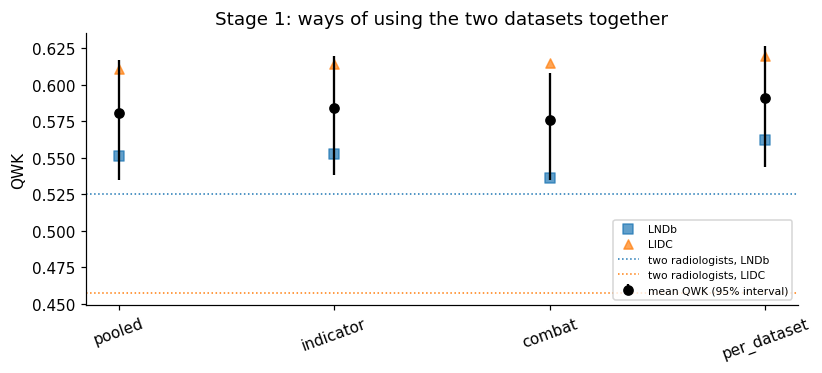

chosen: per_dataset


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
pooling_LNDb_only,0.530,0.455,0.597,0.530,NaN,0.386,NaN,0.609,NaN,NaN,NaN,NaN
pooling_LIDC_only,0.631,0.596,0.665,NaN,0.631,NaN,0.428,NaN,0.473,NaN,NaN,NaN
pooling_pooled,0.581,0.535,0.617,0.551,0.611,0.400,0.406,0.592,0.485,0.000,0.000,0.000
pooling_indicator,0.584,0.538,0.620,0.553,0.614,0.402,0.411,0.592,0.479,0.003,-0.001,0.007
pooling_combat,0.576,0.535,0.608,0.536,0.615,0.382,0.414,0.630,0.485,-0.005,-0.019,0.010
pooling_per_dataset,0.591,0.544,0.627,0.562,0.620,0.400,0.409,0.588,0.491,0.010,0.002,0.018


In [8]:
table = stage_table("pooling_")
together = table.drop(index=["pooling_LNDb_only", "pooling_LIDC_only"])
stage_figure(together, "Stage 1: ways of using the two datasets together")
print("chosen:", chosen["strategy"])
table

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Each dataset alone reaches 0.530 in LNDb and 0.631 in LIDC IDRI. Plain pooling reaches 0.581, with 0.551 in LNDb and 0.611 in LIDC IDRI. Aggregation is the only option that beats plain pooling: 0.591, with an interval of the difference from 0.002 to 0.018. The dataset indicator (0.584) is within the noise of plain pooling (from 0.001 lower to 0.007 higher). ComBat is the only option below plain pooling (0.576), with its loss in LNDb (0.536 against 0.551), although the interval of the difference includes zero (from 0.019 lower to 0.010 higher). Moving the LNDb features onto the scale of LIDC IDRI also removes differences between the two cohorts that are not scanner effects and still carry information about the rating.
  </p>
  <p>
  By the rule fixed in advance, <strong>aggregation</strong> is kept: one model per dataset, with the average of their probabilities for every nodule. LNDb gains the most from it (0.562 against 0.530 alone), because the model trained on the larger LIDC IDRI adds information that the 622 LNDb nodules cannot provide alone. LIDC IDRI loses a little against its model alone (0.620 against 0.631), which the mean of the two datasets accepts in exchange for the gain in LNDb.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How much regularisation each model needs
  </h3>
  <p>
  Every configuration chooses its hyperparameters in the inner folds. For the ordinal model the only hyperparameter is the penalty alpha, which shrinks the coefficients towards zero: a small alpha lets the model follow the training nodules closely, a large one keeps it simple. Two checks show whether the choice was made well.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>The grid check</strong>, fixed in advance: if one of the two ends of the grid is chosen in more than 20% of the outer folds, the best value may lie beyond the grid and the grid must be widened.</li>
    <li style="margin-bottom: 8px;"><strong>The validation curve</strong> (Hastie et al., 2009): the inner score of every penalty, averaged over the 15 outer folds. It shows whether the score has a peak inside the grid, and how flat it is around that peak. A flat top means that the result does not hinge on the exact value chosen.</li>
  </ul>
</div>

In [9]:
# The grid check, fixed in advance: share of the outer folds whose chosen penalty is one of the two ends of its grid.
# Above 0.2 the grid would be too narrow. The other models have grids of two values and are not checked here.
grid_check = summary["share_at_grid_edge"].dropna()
print(f"{len(grid_check)} configurations checked, largest share at an end of the grid: {grid_check.max():.2f}")

# The penalties chosen for the two models of the aggregated configuration, in the 15 outer folds
chosen_penalties = pd.read_csv(MODEL_RESULTS_DIR / "pooling_per_dataset_choices.csv")
pd.crosstab(chosen_penalties["alpha_LNDb"], chosen_penalties["alpha_LIDC"],
            rownames=["penalty of the LNDb model"], colnames=["penalty of the LIDC IDRI model"])

23 configurations checked, largest share at an end of the grid: 1.00


penalty of the LIDC IDRI model,30.0,100.0,300.0
penalty of the LNDb model,,,
30.0,1,1,1
100.0,0,3,1
300.0,1,6,0
1000.0,0,1,0


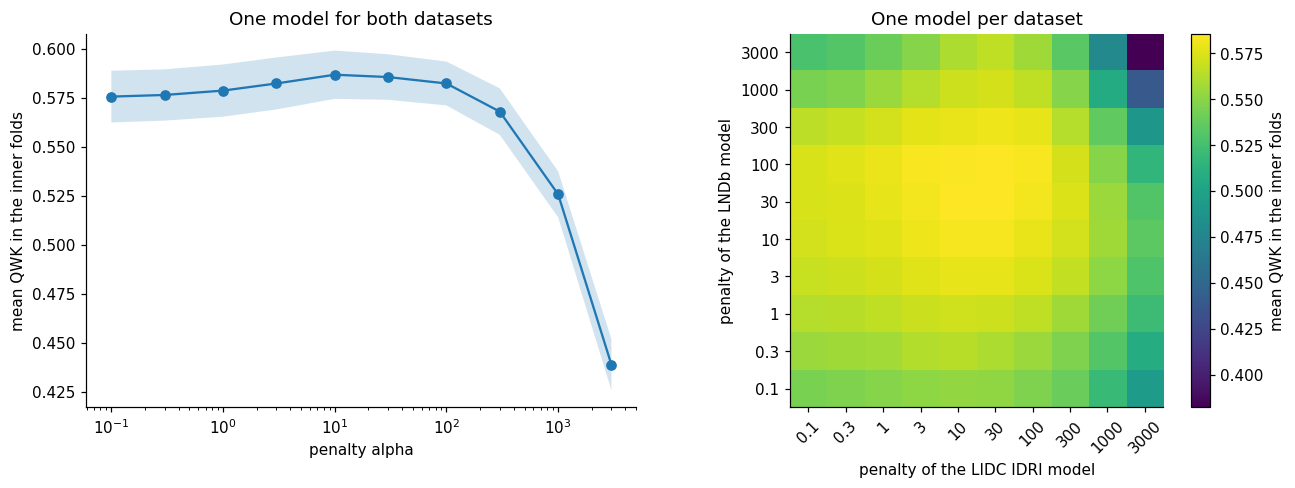

In [10]:
def inner_curve(key):
    """Inner score of every candidate of one configuration (with its best decision rule), averaged over the outer folds."""
    scores = pd.read_csv(MODEL_RESULTS_DIR / f"{key}_inner_scores.csv")
    best_rule = scores.loc[scores.groupby(["seed", "outer_fold", "params"])["score"].idxmax()]
    curve = best_rule.groupby("params")[["score", "se"]].mean()
    curve["params"] = [json.loads(text) for text in curve.index]
    return curve


# Left: one model for both datasets (plain pooling), with one standard error around the mean inner score
pooled = inner_curve("rule_tuned")
pooled["alpha"] = [params["alpha"] for params in pooled["params"]]
pooled = pooled.sort_values("alpha")

# Right: one model per dataset, every pair of penalties (LNDb, LIDC IDRI)
aggregated = inner_curve("pooling_per_dataset")
aggregated["LNDb"] = [params["LNDb"]["alpha"] for params in aggregated["params"]]
aggregated["LIDC"] = [params["LIDC"]["alpha"] for params in aggregated["params"]]
pairs = aggregated.pivot(index="LNDb", columns="LIDC", values="score")

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
left.plot(pooled["alpha"], pooled["score"], marker="o")
left.fill_between(pooled["alpha"], pooled["score"] - pooled["se"], pooled["score"] + pooled["se"], alpha=0.2)
left.set(xscale="log", xlabel="penalty alpha", ylabel="mean QWK in the inner folds",
         title="One model for both datasets")

image = right.imshow(pairs, cmap="viridis", origin="lower")
right.set_xticks(range(len(pairs.columns)), [f"{value:g}" for value in pairs.columns], rotation=45)
right.set_yticks(range(len(pairs.index)), [f"{value:g}" for value in pairs.index])
right.set(xlabel="penalty of the LIDC IDRI model", ylabel="penalty of the LNDb model", title="One model per dataset")
fig.colorbar(image, ax=right, label="mean QWK in the inner folds")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The grids are wide enough: across every configuration of the ordinal model, an end of the grid was chosen in at most 7% of the outer folds (one fold of the confirmation), well below the limit of 20%.
  </p>
  <p>
  With one model per dataset, the inner folds chose a stronger penalty for LNDb than for LIDC IDRI: 300 or more in 8 of the 15 outer folds for LNDb, against 100 in 11 folds for LIDC IDRI. The penalty is added once to a sum over the training nodules, and LNDb has four times fewer of them, so per nodule the LNDb model is regularised about ten times more. This is the expected behaviour: a smaller dataset with noisier labels (71% of the LNDb nodules have a single reader) needs a simpler model, and one penalty for both datasets would have forced a compromise.
  </p>
  <p>
  The validation curve of the model for both datasets is flat at the top: every penalty from 3 to 100 scores within 0.005 of the best (0.587 at 10), while the standard error of the inner score is about 0.012. Beyond 300 the score falls quickly (0.526 at 1000 and 0.439 at 3000), because the model is pushed towards the most frequent rating. The one standard error rule therefore chooses the strongest penalty of the flat top, most often 100: within the noise of the inner folds it is as good as the best, and simpler. The map of the two penalties of the aggregated model shows the same plateau, around 10 to 100 for LNDb and 10 to 30 for LIDC IDRI, so the result does not hinge on the exact values chosen.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 2: which model
  </h3>
  <p>
  With the chosen way of pooling, four models are compared: the ordinal logistic regression, a random forest, histogram gradient boosting and a support vector machine with an RBF kernel. The last three are nominal classifiers, which treat the ratings as unordered categories. Each is wrapped with the method of Frank and Hall (2001): four binary models answer "is the rating above 1, 2, 3, 4?", and the probabilities of the ratings follow from their differences. The order of the ratings is used, and the rare rating 5 is learnt together with the 4s in the question "above 4".
  </p>
  <p>
  A fair comparison needs every model tuned as carefully as the ordinal one, so each gets its own search, in the same inner loop and with one set of hyperparameters per dataset model:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Random forest:</strong> 15 candidates drawn at random from a grid of 288 combinations (Bergstra and Bengio, 2012) of the share of features tried at each split (from a single feature, 0.02 of them, to 0.6), the size of the smallest leaf (1 to 40 nodules), the depth (8, 16 or unlimited) and an optional reweighting of the rare ratings, the hyperparameters that matter most for a forest (Probst, Wright and Boulesteix, 2019). A random sample of a grid finds good values faster than the whole grid, because only a few hyperparameters matter much. The number of trees is not tuned, because more trees never make a forest worse (Probst and Boulesteix, 2018): the inner loop compares candidates with 150 trees and the final model uses 500.</li>
    <li style="margin-bottom: 8px;"><strong>Gradient boosting:</strong> 20 candidates drawn at random from 840 combinations of the learning rate (0.01 to 0.2), the number of leaves of a tree (3 to 63), the size of the smallest leaf (10 to 100) and the L2 penalty (0.1 to 30). The number of boosting rounds is set by early stopping: up to 1000 rounds, stopped when the loss on 20% of the training nodules has not improved for 10 rounds. That 20% comes from the training part only, so the nodules that are evaluated never take part in it.</li>
    <li style="margin-bottom: 8px;"><strong>Support vector machine:</strong> every pair of the penalty C (0.03 to 128) and the width gamma of the RBF kernel (0.0001 to 2), 56 candidates, because the two interact and must be tuned together (Hsu, Chang and Lin, 2003).</li>
  </ul>
  <p>
  Learning rates, penalties and kernel widths are spaced on a logarithmic scale. The grid check and the one standard error rule apply to every model, with every grid ordered from the simplest value to the most complex one: fewer features per split, larger leaves, shallower trees, stronger penalties and wider kernels are simpler.
  </p>
</div>

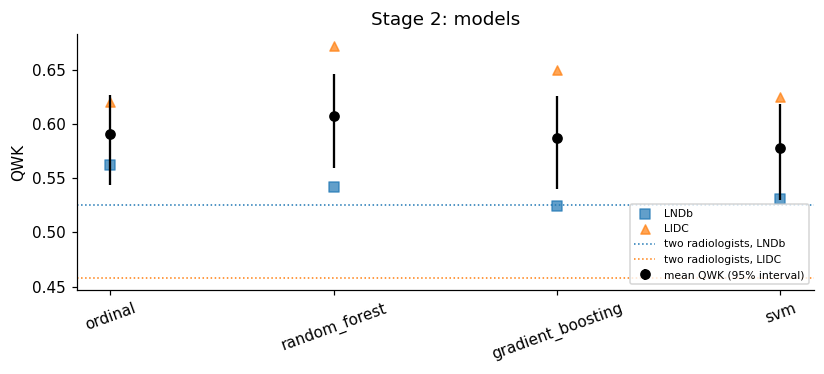

chosen: ordinal


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
model_ordinal,0.591,0.544,0.627,0.562,0.620,0.400,0.409,0.588,0.491,0.000,0.000,0.000
model_random_forest,0.607,0.559,0.646,0.542,0.672,0.442,0.524,0.631,0.501,0.016,-0.007,0.038
model_gradient_boosting,0.587,0.540,0.626,0.524,0.650,0.392,0.444,0.625,0.459,-0.005,-0.026,0.018
model_svm,0.578,0.530,0.618,0.531,0.625,0.406,0.433,0.602,0.474,-0.013,-0.033,0.005


In [11]:
table = stage_table("model_")
stage_figure(table, "Stage 2: models")
print("chosen:", chosen["model"])
table

In [12]:
# The hyperparameters chosen for the three other models: the value chosen most often in the 15 outer folds, and the
# share of folds at an end of its grid (the grid check; only numeric grids of three values or more are checked)
rows = []
for name in ("random_forest", "gradient_boosting", "svm"):
    choices = pd.read_csv(MODEL_RESULTS_DIR / f"model_{name}_choices.csv")
    chosen_values = pd.DataFrame([flat(json.loads(text)) for text in choices["params"]], dtype=object).astype(str)
    edges = edge_share(name, choices)
    for column in chosen_values:
        counts = chosen_values[column].value_counts()
        rows.append({"model": name.replace("_", " "), "hyperparameter": column, "chosen most often": counts.index[0],
                     "in folds": counts.iloc[0], "share at an end of the grid": edges.get(column, np.nan)})
pd.DataFrame(rows).set_index(["model", "hyperparameter"]).round(2)

chosen most often  in folds  share at an end of the grid
model             hyperparameter                                                                   
random forest     min_samples_leaf_LIDC                   40         8                         0.53
                  max_features_LIDC                     0.02         6                         0.40
                  max_depth_LIDC                        None         7                          NaN
                  class_weight_LIDC       balanced_subsample         8                          NaN
                  min_samples_leaf_LNDb                   40         9                         0.60
                  max_features_LNDb                     0.02         8                         0.60
                  max_depth_LNDb                        None         9                          NaN
                  class_weight_LNDb       balanced_subsample         9                          NaN
gradient boosting min_samples_leaf_LIDC                  100         8                         0.60
                  max_leaf_nodes_LIDC                     15         7                         0.13
                  learning_rate_LIDC                    0.01        11                         0.73
                  l2_regularization_LIDC                30.0         7                         0.47
                  min_samples_leaf_LNDb                  100        11                         0.73
                  max_leaf_nodes_LNDb                     15         8                         0.13
                  learning_rate_LNDb                    0.01        10                         0.73
                  l2_regularization_LNDb                30.0         8                         0.53
svm               C_LIDC                             0.03125         5                         0.40
                  gamma_LIDC                 0.0001220703125         6                         0.40
                  C_LNDb                             0.03125         8                         0.53
                  gamma_LNDb                 0.0001220703125         9                         0.60

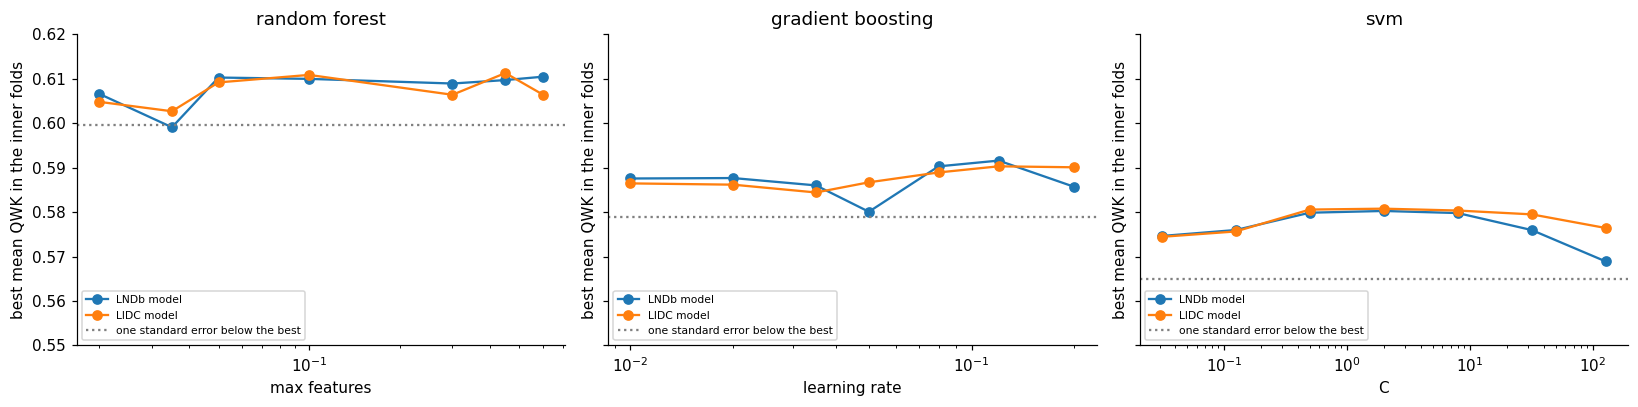

In [13]:
# Profile curves: for each value of the main hyperparameter of each model, the best inner score that a candidate with
# that value reaches (in each outer fold, then averaged over the 15 folds), for the LNDb model and the LIDC IDRI model.
# The dotted line is one standard error below the best score: every value above it is as good as the best within the noise.
main = {"random_forest": "max_features", "gradient_boosting": "learning_rate", "svm": "C"}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for axis, (name, key) in zip(axes, main.items()):
    scores = pd.read_csv(MODEL_RESULTS_DIR / f"model_{name}_inner_scores.csv")
    params = [json.loads(text) for text in scores["params"]]
    best_score = 0
    for dataset in ("LNDb", "LIDC"):
        values = [own[dataset][key] for own in params]
        best = scores.assign(value=values).groupby(["seed", "outer_fold", "value"])["score"].max()
        profile = best.groupby("value").mean()
        axis.plot(profile.index, profile.values, marker="o", label=f"{dataset} model")
        best_score = max(best_score, profile.max())
    axis.axhline(best_score - scores["se"].mean(), color="grey", linestyle=":", label="one standard error below the best")
    axis.set(xscale="log", xlabel=key.replace("_", " "), ylabel="best mean QWK in the inner folds",
             title=name.replace("_", " "), ylim=(0.55, 0.62))
    axis.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  With every model tuned, the random forest reaches the highest mean QWK, 0.607 (from 0.559 to 0.646), but its difference to the ordinal model, 0.016 higher, has an interval from 0.007 lower to 0.038 higher, which includes zero. Gradient boosting (0.587) and the support vector machine (0.578) are equal to the ordinal model within the noise (differences from 0.026 lower to 0.018 higher, and from 0.033 lower to 0.005 higher). By the rule fixed in advance, the <strong>ordinal logistic regression</strong> is kept: it is the simplest model, its coefficients can be read directly, and no flexible model beats it beyond the noise.
  </p>
  <p>
  The comparison still says something useful. The random forest is much better in LIDC IDRI (0.672 against 0.620) and has a clearly higher balanced accuracy (0.442 in LNDb and 0.524 in LIDC IDRI, against 0.400 and 0.409), because the inner folds chose to reweight the rare ratings in most folds. It is worse in LNDb (0.542 against 0.562), where 622 nodules are too few for a flexible model, and its MAE in LNDb is higher (0.631 against 0.588). The two models are strong in different places, which suggests that combining them could help.
  </p>
  <p>
  The grid check flags the three flexible models: an end of a grid was chosen in up to 73% of the outer folds (the smallest learning rate and the largest leaves for boosting, a single feature per split for the forest, the smallest C and gamma for the SVM). The profile curves show why. Their best values lie inside the grids (the SVM peaks at C = 2, boosting at a learning rate of 0.12, and the forest scores within 0.005 of its best anywhere from 0.05 to 0.6 of the features), and almost every value stays above the dotted line, within one standard error of the best. The ends were therefore chosen by the one standard error rule as the simplest of many equally good candidates, not because the score keeps rising towards them, and a wider grid would not change that; for the forest, one feature per split is already the smallest possible value. On these data the three models are insensitive to their hyperparameters, so the comparison with the ordinal model does not hinge on the exact values chosen.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 3: the training label
  </h3>
  <p>
  A nodule read by several radiologists has several ratings. We compare training on the mean rating of each nodule rounded half up (A) with training on every reading, each with the region and the rating of its radiologist and a weight of one divided by the number of readers, so that every nodule weighs the same (B; Raykar et al., 2010). The evaluation always uses label A.
  </p>
</div>

In [14]:
table = stage_table("label_")
print("chosen:", chosen["label"])
table

chosen: A


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
label_A,0.591,0.544,0.627,0.562,0.620,0.400,0.409,0.588,0.491,0.000,0.000,0.000
label_B,0.593,0.547,0.630,0.549,0.637,0.416,0.440,0.597,0.509,0.001,-0.012,0.014


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Training on every reading (B) gives the same mean QWK as training on the mean label (A): 0.593 against 0.591, a difference of 0.001 (from 0.012 lower to 0.014 higher). B is better in LIDC IDRI (0.637 against 0.620) and worse in LNDb (0.549 against 0.562). Since nothing is gained, the simpler <strong>label A</strong> is kept.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 4: the 1 to 3 scale
  </h3>
  <p>
  The 1 to 3 scale (benign, indeterminate, suspicious) follows the decision a clinician takes. It can be obtained by grouping the predictions on the 1 to 5 scale, or by training directly on it. Its ceiling is lower than on the 1 to 5 scale, so the two scales are judged against their own ceilings.
  </p>
</div>

In [15]:
print("agreement between two radiologists on the 1 to 3 scale:", ceiling["QWK 1 to 3"].round(3).to_dict())
stage_table("scale3_")[["mean_qwk", "low", "high", "qwk_LNDb", "qwk_LIDC"] + difference]

agreement between two radiologists on the 1 to 3 scale: {'LIDC': 0.311, 'LNDb': 0.437}


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,difference,difference_low,difference_high
config,,,,,,,,
scale3_collapsed,0.498,0.453,0.538,0.456,0.540,NaN,NaN,NaN
scale3_direct,0.492,0.442,0.535,0.445,0.538,-0.006,-0.025,0.011


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  On the 1 to 3 scale, grouping the 1 to 5 predictions reaches a mean QWK of 0.498 (from 0.453 to 0.538), with 0.456 in LNDb and 0.540 in LIDC IDRI. Training directly on the 1 to 3 scale gives 0.492, which is no better (difference 0.006 lower, from 0.025 lower to 0.011 higher). The grouped predictions are kept, so one model serves both scales. Both values are above the agreement between radiologists on this scale (0.437 and 0.311 for two radiologists, 0.42 and 0.40 for one radiologist against the others). The 1 to 3 scale has fewer levels, so each disagreement weighs more, which explains why every QWK is lower than on the 1 to 5 scale.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 5: three extensions of the chosen model
  </h3>
  <p>
  The chosen configuration has two known weaknesses: it is drawn towards rating 3, and the random forest beat it in LIDC IDRI and in balanced accuracy without beating it overall. Three extensions address them, each with its hyperparameters chosen in the inner folds and one set per dataset model:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Rare ratings weighted up:</strong> the ordinal model trained with every nodule weighted by one divided by the share of its rating, raised to a power of 0 (no change), 0.5 or 1 (every rating weighs the same in total). This is what gave the random forest its higher balanced accuracy, and it may let the ordinal model predict more 4s and 5s.</li>
    <li style="margin-bottom: 8px;"><strong>Elastic net:</strong> a logistic regression with an L1 and an L2 penalty (Zou and Hastie, 2005), wrapped with the method of Frank and Hall. The L1 part sets the coefficients of unhelpful features exactly to zero, so it selects features inside every fit, with the rating, but only on the training part of each fold (Ambroise and McLachlan, 2002). The strength of the penalty and the share of L1 are chosen in the inner folds.</li>
    <li style="margin-bottom: 8px;"><strong>Average of the ordinal model and the random forest:</strong> for each dataset, the probabilities w times those of the ordinal model plus (1 minus w) times those of the forest, with w in 1, 0.75, 0.5, 0.25 and 0. The weight 1 is the ordinal model alone and 0 the forest alone, so the inner folds can also choose the ordinal model for LNDb and the forest for LIDC IDRI. A weighted average is a constrained form of stacking, the most stable one when data are few (Breiman, 1996); full stacking, with a second model trained on the predictions of the first ones, would need yet another level of cross validation and would overfit the 622 LNDb nodules. Each of the two models keeps the hyperparameters that its own inner loop chose in that outer fold, which is fair because they were chosen on the training part of that fold only.</li>
  </ul>
  <p>
  Each extension is compared with the chosen configuration by the rule of every stage: it replaces it only if the 95% interval of the difference lies above zero. Balanced accuracy and MAE are shown as well, because an extension may trade agreement for better recall of the rare ratings.
  </p>
</div>

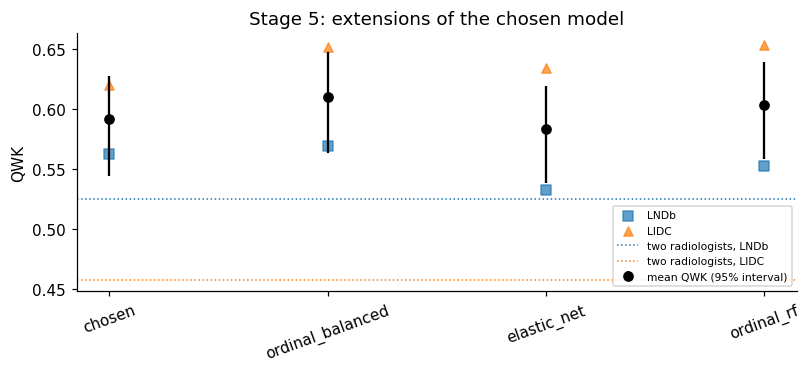

final model: ordinal_balanced


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
extension_chosen,0.591,0.544,0.627,0.562,0.620,0.400,0.409,0.588,0.491,0.000,0.000,0.000
extension_ordinal_balanced,0.610,0.563,0.647,0.569,0.651,0.439,0.496,0.599,0.494,0.019,0.002,0.035
extension_elastic_net,0.583,0.538,0.619,0.532,0.634,0.398,0.428,0.613,0.479,-0.008,-0.024,0.007
extension_ordinal_rf,0.603,0.558,0.639,0.552,0.653,0.419,0.464,0.605,0.488,0.011,-0.000,0.023


In [16]:
# Stage 5: the chosen configuration ("chosen") against its three extensions
table = stage_table("extension_")
stage_figure(table, "Stage 5: extensions of the chosen model")
print("final model:", chosen.get("final_model", chosen["model"]))
table

In [17]:
# What the inner folds chose for each extension, in the 15 outer folds
average = pd.read_csv(MODEL_RESULTS_DIR / "extension_ordinal_rf_choices.csv")
weighted = pd.read_csv(MODEL_RESULTS_DIR / "extension_ordinal_balanced_choices.csv")
display(pd.crosstab(average["w_LNDb"], average["w_LIDC"], rownames=["weight of the ordinal model, LNDb"],
                    colnames=["weight of the ordinal model, LIDC IDRI"]))
display(weighted[["class_power_LNDb", "class_power_LIDC"]].apply(lambda column: column.value_counts()).fillna(0).astype(int)
        .rename_axis("power of the class weights"))

# Elastic net: how many of the 63 features keep a non zero coefficient, refitted on every nodule of each dataset
# with the hyperparameters chosen most often (a description of the selection, not an evaluation)
net = pd.read_csv(MODEL_RESULTS_DIR / "extension_elastic_net_choices.csv")
for dataset in ("LNDb", "LIDC"):
    params = json.loads(net["params"].mode()[0])[dataset]
    rows = nodules[nodules["dataset"] == dataset]
    model = make_model("elastic_net", params).fit(rows[features], rows["rating"])
    used = np.any([binary.coef_[0] != 0 for binary in model[-1].models_], axis=0)
    print(f"{dataset}: C {params['C']}, L1 share {params['l1_ratio']}: {used.sum()} of {len(features)} features kept")

"weight of the ordinal model, LIDC IDRI",0.00,0.50,0.75,1.00
"weight of the ordinal model, LNDb",,,,
0.00,0,0,1,1
0.25,0,0,2,2
0.75,0,2,0,0
1.00,1,3,3,0


,class_power_LNDb,class_power_LIDC
power of the class weights,,
0.0,1,0
0.5,7,15
1.0,7,0


LNDb: C 0.1, L1 share 1.0: 24 of 63 features kept


LIDC: C 0.1, L1 share 1.0: 47 of 63 features kept


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Weighting the rare ratings up is the only extension that beats the chosen configuration beyond the noise: 0.610 (from 0.563 to 0.647), 0.019 more, with an interval of the difference from 0.002 to 0.035. It gains in both datasets, above all in LIDC IDRI (0.651 against 0.620, and 0.569 against 0.562 in LNDb), and its balanced accuracy rises clearly (0.439 in LNDb and 0.496 in LIDC IDRI, against 0.400 and 0.409), at the cost of a slightly larger MAE in LNDb (0.599 against 0.588). The inner folds chose a power of 0.5 for LIDC IDRI in every fold, and 0.5 or 1 for LNDb.
  </p>
  <p>
  For LNDb they also chose the strongest penalty, 30000, in 14 of the 15 outer folds, at the end of a grid that had already been widened once from 3000. This end is not a grid that stops too early but a natural limit: at that penalty the coefficients of the LNDb model almost vanish (their absolute sum falls from 2.9 at a penalty of 300 to 0.2), so the LNDb model keeps little more than the reweighted frequencies of the ratings in LNDb, and the distinctions between LNDb nodules come from the model trained on LIDC IDRI. With the rare ratings weighted up and only 18 LNDb nodules rated 5, a model trained on LNDb alone would overfit them, and the inner folds prefer to give it up.
  </p>
  <p>
  The average of the ordinal model and the random forest reaches 0.603, 0.011 more, but its interval starts just below zero (from 0.0002 lower to 0.023 higher). Its weights confirm that the two models are complementary: for LNDb the inner folds mostly kept the ordinal model alone (weight 1 in 7 of the 15 folds), for LIDC IDRI they mixed both. The elastic net reaches 0.583, within the noise but below the chosen configuration. It kept 24 of the 63 features for LNDb and 47 for LIDC IDRI: the robust features left by notebook 05 are already a lean set, and dropping more of them does not help. For LNDb it also chose its strongest penalty in 6 of the 15 folds, the same tendency of the LNDb model to give up its own features.
  </p>
  <p>
  By the rule fixed in advance, the <strong>ordinal model with the rare ratings weighted up</strong> becomes the final configuration. Three extensions were tried, which raises the risk of a gain by chance; the confirmation on new seeds below is the safeguard.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The chosen configuration on new splits
  </h3>
  <p>
  Every stage chose among options on the same outer folds, which makes the reported score slightly optimistic. The chosen configuration is therefore evaluated again on three new seeds, which it never saw while being chosen.
  </p>
</div>

In [18]:
# The chosen configuration on the seeds used for choosing, and on three new seeds
chosen_key = f"label_{chosen['label']}"
final_model = chosen.get("final_model", chosen["model"])          # the stage 2 model, or the stage 5 extension
tag = f"{final_model}_{chosen['strategy']}_{chosen['label']}"         # the result files carry the final configuration
confirmation = np.load(MODEL_RESULTS_DIR / f"confirmation_{tag}.npz", allow_pickle=True)
print("chosen:", chosen)
summary.loc[[chosen_key, "confirmation"], columns].round(3)

chosen: {'strategy': 'per_dataset', 'model': 'ordinal', 'label': 'A', 'final_model': 'ordinal_balanced'}


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC
config,,,,,,,,,
label_A,0.591,0.544,0.627,0.562,0.620,0.400,0.409,0.588,0.491
confirmation,0.606,0.559,0.644,0.564,0.647,0.429,0.481,0.599,0.489


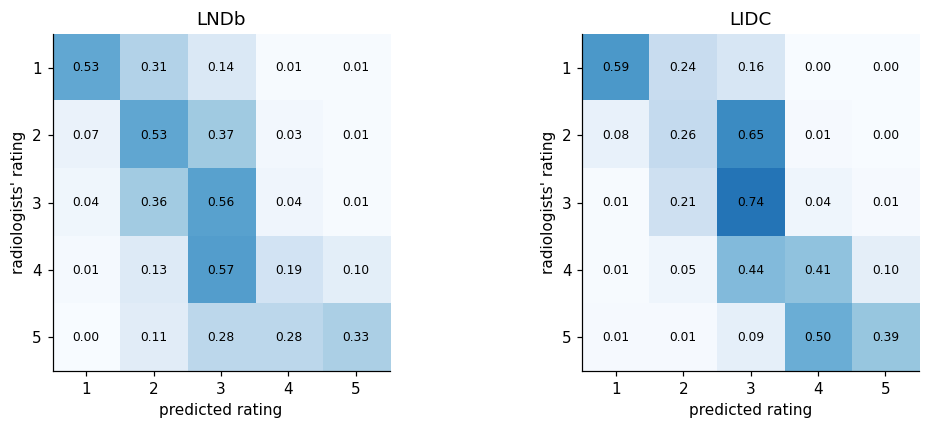

In [19]:
# Confusion matrices of the chosen configuration (first new seed), per dataset; each row sums to 1
decoded = confirmation["decoded"][0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, dataset in zip(axes, ("LNDb", "LIDC")):
    rows = (nodules["dataset"] == dataset).to_numpy()
    matrix = confusion_matrix(nodules["rating"][rows], decoded[rows], labels=range(1, 6), normalize="true")
    axis.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            axis.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8)
    axis.set(xticks=range(5), xticklabels=range(1, 6), yticks=range(5), yticklabels=range(1, 6),
             xlabel="predicted rating", ylabel="radiologists' rating", title=dataset)
plt.tight_layout()
plt.show()

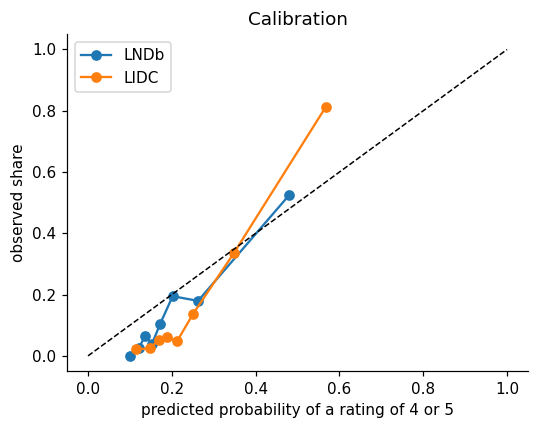

In [20]:
# Calibration: predicted probability of a rating of 4 or 5 against the observed share, in 8 groups of equal size
# (probabilities averaged over the three new seeds)
suspicious = confirmation["proba"][:, :, 3:].sum(axis=2).mean(axis=0)
is_suspicious = nodules["rating"].to_numpy() >= 4

fig, ax = plt.subplots(figsize=(5, 4))
for dataset in ("LNDb", "LIDC"):
    rows = (nodules["dataset"] == dataset).to_numpy()
    groups = pd.qcut(suspicious[rows], 8, duplicates="drop")
    predicted = pd.Series(suspicious[rows]).groupby(groups).mean()
    observed = pd.Series(is_suspicious[rows]).groupby(groups).mean()
    ax.plot(predicted, observed, marker="o", label=dataset)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)          # perfect calibration
ax.set(xlabel="predicted probability of a rating of 4 or 5", ylabel="observed share", title="Calibration")
ax.legend()
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  On three new seeds the final configuration reaches a mean QWK of 0.606 (from 0.559 to 0.644), with 0.564 in LNDb and 0.647 in LIDC IDRI, against 0.610 on the seeds used for choosing: the choices made the estimate about 0.005 optimistic, much less than its uncertainty. The gain of the weights holds on these new seeds: 0.017 above the ordinal model without weights on the same splits (from 0.002 to 0.033). On the 1 to 5 scale the model agrees with the label at least as well as one radiologist agrees with the others (0.527), and on the 1 to 3 scale it reaches 0.509 (0.472 in LNDb and 0.546 in LIDC IDRI, on the seeds used for choosing).
  </p>
  <p>
  The weights move the predictions away from rating 3. In LIDC IDRI, 41% of the nodules rated 4 and 39% of those rated 5 are now predicted exactly (32% and 21% without the weights), and in LNDb 19% and 33% (11% and 22%). The price is paid in the middle: 74% of the LIDC IDRI nodules rated 3 are predicted 3 (88% without the weights). The model is still drawn towards rating 3 for many nodules rated 2 in LIDC IDRI (65%) and rated 4 in LNDb (57%). Large errors remain rare: a nodule rated 1 is almost never predicted 4 or 5, and a nodule rated 5 almost never 1.
  </p>
  <p>
  The weights have a known cost: the probabilities are no longer calibrated. The model gives a rating of 4 or 5 a mean probability of 0.20 in LNDb and 0.25 in LIDC IDRI, against observed shares of 0.14 and 0.19, and it overestimates the least suspicious nodules (about 0.10 to 0.20 where 0 to 0.06 are observed). This is expected: weighting a rating up tells the model that it is more frequent than it is. The rating it chooses is better, but its probabilities should not be read as risks without a recalibration fitted on the training folds (Van Calster et al., 2019).
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   What the model looks at
  </h3>
  <p>
  Permutation importance: on the outer folds of one seed, each feature is shuffled in turn inside the held out fold and the drop of the mean QWK is recorded (Molnar, 2022). A large drop means that the model relies on that feature. Features that are strongly correlated share their importance, which is why notebook 05 removed the most redundant ones.
  </p>
</div>

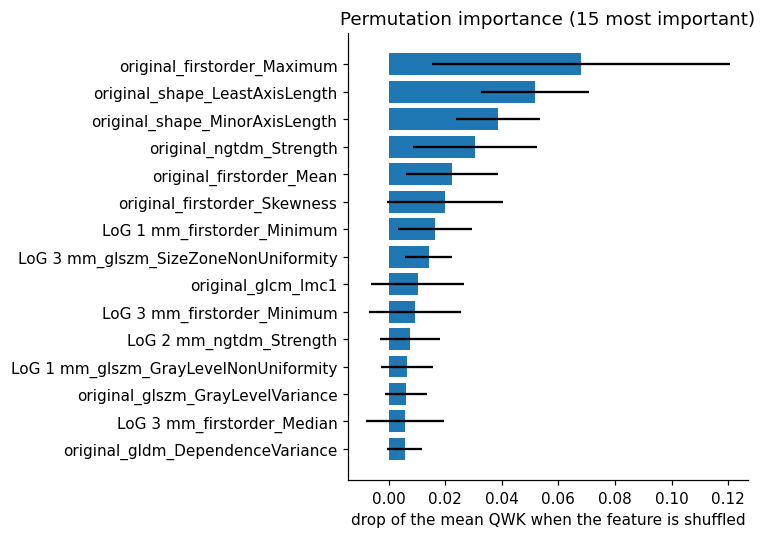

In [21]:
# The 15 most important features, with the standard deviation over folds and repeats
importance = pd.read_csv(MODEL_RESULTS_DIR / f"permutation_importance_{tag}.csv", index_col=0)
top = importance.head(15).iloc[::-1]
short_names = [name.replace("log-sigma-", "LoG ").replace("-0-mm-3D", " mm") for name in top.index]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(short_names, top["importance"], xerr=top["sd"], color="tab:blue")
ax.set(xlabel="drop of the mean QWK when the feature is shuffled", title="Permutation importance (15 most important)")
plt.tight_layout()
plt.show()

In [22]:
# How the predicted probability of a rating of 4 or 5 grows with the diameter, against the observed share
size = pd.cut(nodules["roi_diameter_mm"], [0, 5, 8, 12, 20, 100],
              labels=["under 5 mm", "5 to 8", "8 to 12", "12 to 20", "20 mm or more"])
pd.DataFrame({
    "nodules": size.value_counts(sort=False),
    "observed share of 4 and 5": pd.Series(is_suspicious).groupby(size, observed=False).mean(),
    "predicted probability": pd.Series(suspicious).groupby(size, observed=False).mean(),
}).round(2)

,nodules,observed share of 4 and 5,predicted probability
roi_diameter_mm,,,
under 5 mm,1266,0.03,0.15
5 to 8,1201,0.09,0.20
8 to 12,414,0.36,0.34
12 to 20,264,0.77,0.53
20 mm or more,92,0.80,0.63


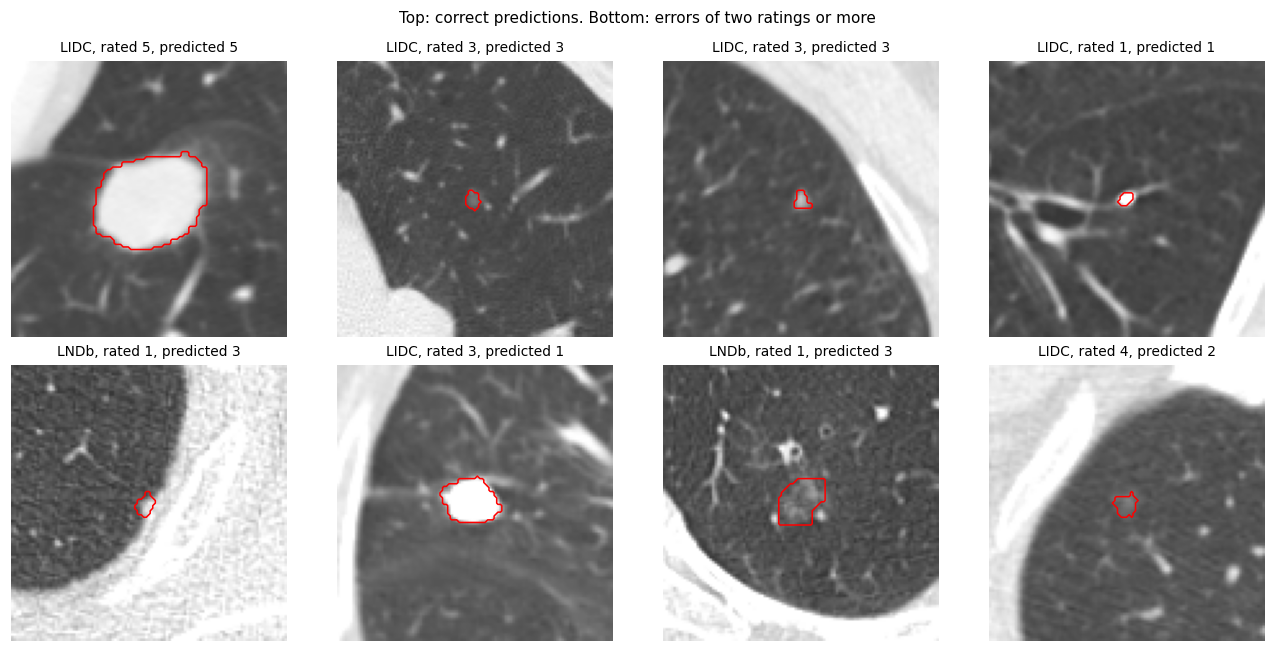

In [23]:
# Central axial slice with the consensus contour: four correct predictions and four errors of two ratings or more
manifest = pd.concat([pd.read_csv(LNDB_MANIFEST_FILE), pd.read_csv(LIDC_MANIFEST_FILE)])
file_of = dict(zip(manifest["patch_id"], manifest["file"]))
error = np.abs(decoded - nodules["rating"].to_numpy())
rng = np.random.default_rng(0)
correct = rng.choice(np.flatnonzero(error == 0), 4, replace=False)
wrong = rng.choice(np.flatnonzero(error >= 2), 4, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, row in zip(axes.ravel(), list(correct) + list(wrong)):
    nodule = nodules.iloc[row]
    patch = np.load(PATCHES_DIR / file_of[nodule["patch_id"]])
    rois = np.load(ROI_DIR / f"{nodule['patch_id']}.npz")
    axis.imshow(patch[CENTRE_INDEX], cmap="gray", vmin=-1350, vmax=150)      # lung window
    axis.contour(rois["consensus"][CENTRE_INDEX], levels=[0.5], colors="red", linewidths=1)
    axis.set_title(f"{nodule['dataset']}, rated {nodule['rating']}, predicted {decoded[row]}", fontsize=9)
    axis.axis("off")
fig.suptitle("Top: correct predictions. Bottom: errors of two ratings or more", fontsize=10)
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The model relies on the features that radiologists use. The most important are the brightest value inside the nodule and its mean density (first order maximum and mean), which separate calcified and solid nodules from ground glass ones; the two shortest axes (least and minor axis length), which measure its size; and texture features (NGTDM strength, first order skewness, the size zone non uniformity of the LoG image at 3 mm, the GLCM informational correlation) that describe how heterogeneous it is. Shuffling any of the five most important features lowers the mean QWK by 0.022 to 0.068, and 51 of the 63 features lower it at all.
  </p>
  <p>
  The predicted probability of a rating of 4 or 5 still grows with size, but less steeply than the observed share: 0.15 against 0.03 below 5 mm, 0.20 against 0.09 from 5 to 8 mm, 0.34 against 0.36 from 8 to 12 mm, 0.53 against 0.77 from 12 to 20 mm and 0.63 against 0.80 from 20 mm. Part of this is the reweighting, which gives small nodules more probability of a rare rating, and part is the LNDb model, which almost ignores the features. The examples of large errors are two small LNDb nodules rated 1 but predicted 3, one against the pleura and one with an irregular, partly ground glass region; a small LIDC IDRI nodule rated 4 but predicted 2; and a large dense nodule rated 3 but predicted 1, whose region is brighter than the top of the display window (150 HU), which suggests calcification, a classic benign sign, while the radiologists judged it indeterminate, probably from context that the patch does not show.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Conclusions and limits
  </h3>
  <p>
  The final configuration is an <strong>ordinal logistic regression on 63 robust PyRadiomics features, with the rare ratings weighted up, one model per dataset with its own penalty and their probabilities averaged, trained on the mean rating and with the decision rule chosen in the inner folds</strong>. On new splits it reaches a mean QWK of 0.606 (95% interval from 0.559 to 0.644) on the 1 to 5 scale, 0.564 in LNDb and 0.647 in LIDC IDRI, with a balanced accuracy of 0.429 and 0.481. It agrees with the label at least as well as one radiologist agrees with the others, and adds about 0.24 to the diameter alone. The random forest, gradient boosting, the SVM, ComBat harmonisation, training on single readings, the elastic net and the average with the random forest did not beat it beyond the noise.
  </p>
  <p>
  Limits:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The label is a subjective rating of malignancy by radiologists, not a diagnosis confirmed by biopsy or follow up, so the model learns how radiologists rate nodules, not whether a nodule is cancer.</li>
    <li style="margin-bottom: 8px;">LNDb is small (622 nodules, 18 rated 5). With the weights, its own model almost ignores the features, so the LNDb nodules are in practice scored by the model learnt on LIDC IDRI, adjusted to the rating habits of LNDb.</li>
    <li style="margin-bottom: 8px;">The weights make the probabilities uncalibrated: the predicted rating is better, but the probabilities need a recalibration before they can be read as risks.</li>
    <li style="margin-bottom: 8px;">All results come from cross validation on the training data of the two datasets. They are not an evaluation on a separate test set or on another hospital.</li>
    <li style="margin-bottom: 8px;">Many options were compared across the stages. The confirmation on new seeds shows little optimism (about 0.005), but the margin of the final choice over the unweighted model is small (0.017, interval from 0.002 to 0.033).</li>
    <li style="margin-bottom: 8px;">The random forest, gradient boosting and the support vector machine are insensitive to their hyperparameters on these data, so the values chosen for them are the simplest of many equally good ones rather than a sharp optimum.</li>
    <li style="margin-bottom: 8px;">The features describe only the region drawn by the radiologists. Context outside the nodule, which radiologists also look at, is not used.</li>
  </ul>
</div>